In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('Task 3 and 4_Loan_Data.csv')

print("Shape:", df.shape)
df.head()

Shape: (10000, 8)


,customer_id,credit_lines_outstanding,loan_amt_outstanding,total_debt_outstanding,income,years_employed,fico_score,default
0,8153374,0,5221.545193,3915.471226,78039.38546,5,605,0
1,7442532,5,1958.928726,8228.752520,26648.43525,2,572,1
2,2256073,0,3363.009259,2027.830850,65866.71246,4,602,0
3,4885975,0,4766.648001,2501.730397,74356.88347,5,612,0
4,4700614,1,1345.827718,1768.826187,23448.32631,6,631,0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10000 non-null  int64  
 1   credit_lines_outstanding  10000 non-null  int64  
 2   loan_amt_outstanding      10000 non-null  float64
 3   total_debt_outstanding    10000 non-null  float64
 4   income                    10000 non-null  float64
 5   years_employed            10000 non-null  int64  
 6   fico_score                10000 non-null  int64  
 7   default                   10000 non-null  int64  
dtypes: float64(3), int64(5)
memory usage: 625.1 KB


In [3]:
# Check for duplicate customers
print("Duplicate customer_ids:", df['customer_id'].duplicated().sum())

# Summary statistics
df.describe()

Duplicate customer_ids: 0


,customer_id,credit_lines_outstanding,loan_amt_outstanding,total_debt_outstanding,income,years_employed,fico_score,default
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.974577e+06,1.461200,4159.677034,8718.916797,70039.901401,4.552800,637.557700,0.185100
std,2.293890e+06,1.743846,1421.399078,6627.164762,20072.214143,1.566862,60.657906,0.388398
min,1.000324e+06,0.000000,46.783973,31.652732,1000.000000,0.000000,408.000000,0.000000
25%,2.977661e+06,0.000000,3154.235371,4199.836020,56539.867903,3.000000,597.000000,0.000000
50%,4.989502e+06,1.000000,4052.377228,6732.407217,70085.826330,5.000000,638.000000,0.000000
75%,6.967210e+06,2.000000,5052.898103,11272.263740,83429.166133,6.000000,679.000000,0.000000
max,8.999789e+06,5.000000,10750.677810,43688.784100,148412.180500,10.000000,850.000000,1.000000


In [4]:
# Default distribution
print(df['default'].value_counts())
print("Default rate:", df['default'].mean())

default
0    8149
1    1851
Name: count, dtype: int64
Default rate: 0.1851


In [6]:
df.groupby('default').mean()

,customer_id,credit_lines_outstanding,loan_amt_outstanding,total_debt_outstanding,income,years_employed,fico_score
default,,,,,,,
0,4.967005e+06,0.744140,4092.629025,6322.164549,69883.889804,4.765247,646.938765
1,5.007914e+06,4.618044,4454.854897,19270.582961,70726.740140,3.617504,596.257699


In [7]:
df.drop(columns=['customer_id']).corr()

,credit_lines_outstanding,loan_amt_outstanding,total_debt_outstanding,income,years_employed,fico_score,default
credit_lines_outstanding,1.000000,0.080249,0.852210,0.022272,-0.087900,-0.258177,0.862815
loan_amt_outstanding,0.080249,1.000000,0.397403,0.835815,-0.158416,-0.031373,0.098978
total_debt_outstanding,0.852210,0.397403,1.000000,0.394397,-0.174353,-0.232246,0.758868
income,0.022272,0.835815,0.394397,1.000000,0.001814,-0.010528,0.016309
years_employed,-0.087900,-0.158416,-0.174353,0.001814,1.000000,0.255873,-0.284506
fico_score,-0.258177,-0.031373,-0.232246,-0.010528,0.255873,1.000000,-0.324515
default,0.862815,0.098978,0.758868,0.016309,-0.284506,-0.324515,1.000000


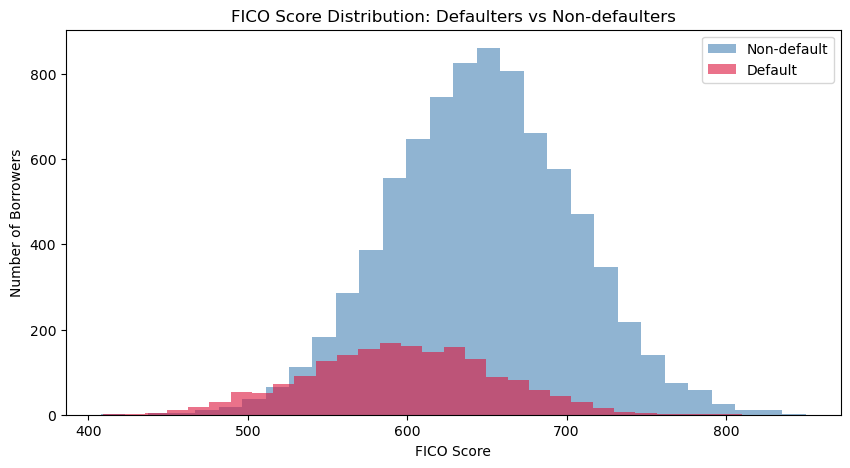

In [8]:
import matplotlib.pyplot as plt

# Plot 1: FICO score distribution by default class
plt.figure(figsize=(10, 5))
plt.hist(df[df['default']==0]['fico_score'], bins=30, alpha=0.6, label='Non-default', color='steelblue')
plt.hist(df[df['default']==1]['fico_score'], bins=30, alpha=0.6, label='Default', color='crimson')
plt.xlabel('FICO Score')
plt.ylabel('Number of Borrowers')
plt.title('FICO Score Distribution: Defaulters vs Non-defaulters')
plt.legend()
plt.show()

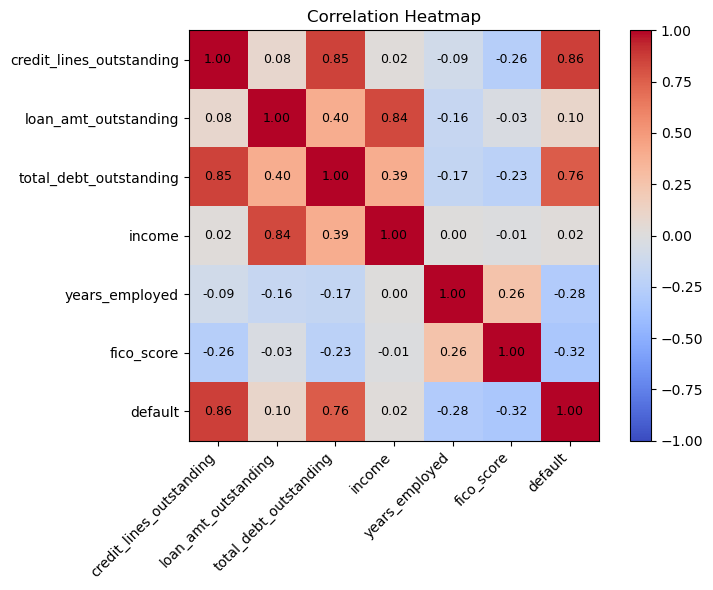

In [9]:
# Plot 2: Correlation heatmap
plt.figure(figsize=(8, 6))
corr = df.drop(columns=['customer_id']).corr()
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), corr.columns)

# Write the correlation number in each cell
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', color='black', fontsize=9)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

# Define our features (X) and target (y)
X = df.drop(columns=['customer_id', 'default'])
y = df['default']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)
print("Default rate in train:", y_train.mean())
print("Default rate in test:", y_test.mean())

Training set size: (8000, 6)
Test set size: (2000, 6)
Default rate in train: 0.185125
Default rate in test: 0.185


In [11]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data, then transform both train and test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Peek at the result — first few scaled training rows
print("Mean of each scaled feature (should be ~0):")
print(X_train_scaled.mean(axis=0))
print("\nStd of each scaled feature (should be ~1):")
print(X_train_scaled.std(axis=0))

Mean of each scaled feature (should be ~0):
[ 3.33066907e-17 -2.29150032e-16 -1.11910481e-16 -1.61648472e-16
  8.88178420e-18  4.17443857e-16]

Std of each scaled feature (should be ~1):
[1. 1. 1. 1. 1. 1.]


In [12]:
from sklearn.linear_model import LogisticRegression

# Create the model
log_reg = LogisticRegression(random_state=42, max_iter=1000)

# Train it on the scaled training data
log_reg.fit(X_train_scaled, y_train)

# Predict probabilities on the test set
y_pred_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# Predict binary labels (0 or 1) on the test set
y_pred_lr = log_reg.predict(X_test_scaled)

# Look at the coefficients so we can interpret the model
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': log_reg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print("Model coefficients (sorted by magnitude):")
print(coef_df)
print("\nIntercept:", log_reg.intercept_[0])

Model coefficients (sorted by magnitude):
                    feature  coefficient
0  credit_lines_outstanding     8.747702
2    total_debt_outstanding     3.837128
4            years_employed    -2.903099
3                    income    -2.354434
5                fico_score    -1.135559
1      loan_amt_outstanding     0.118859

Intercept: -13.198014441130004


In [13]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# Train it
rf.fit(X_train_scaled, y_train)

# Predict probabilities and labels on test set
y_pred_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]
y_pred_rf = rf.predict(X_test_scaled)

# Feature importances
imp_df = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("Feature importances (Random Forest):")
print(imp_df)

Feature importances (Random Forest):
                    feature  importance
0  credit_lines_outstanding    0.585093
2    total_debt_outstanding    0.280504
4            years_employed    0.049697
5                fico_score    0.040889
3                    income    0.029224
1      loan_amt_outstanding    0.014593


In [14]:
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

# --- Logistic Regression ---
print("=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)
print(f"AUC-ROC: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['No Default', 'Default']))

# --- Random Forest ---
print("=" * 60)
print("RANDOM FOREST")
print("=" * 60)
print(f"AUC-ROC: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['No Default', 'Default']))

LOGISTIC REGRESSION
AUC-ROC: 1.0000

Confusion Matrix:
[[1630    0]
 [   2  368]]

Classification Report:
              precision    recall  f1-score   support

  No Default       1.00      1.00      1.00      1630
     Default       1.00      0.99      1.00       370

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

RANDOM FOREST
AUC-ROC: 0.9998

Confusion Matrix:
[[1627    3]
 [   5  365]]

Classification Report:
              precision    recall  f1-score   support

  No Default       1.00      1.00      1.00      1630
     Default       0.99      0.99      0.99       370

    accuracy                           1.00      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       1.00      1.00      1.00      2000



In [15]:
def expected_loss(
    credit_lines_outstanding,
    loan_amt_outstanding,
    total_debt_outstanding,
    income,
    years_employed,
    fico_score,
    recovery_rate=0.10
):
    """
    Predicts the expected loss on a loan.
    
    Formula: Expected Loss = PD × EAD × LGD
    where LGD = 1 - recovery_rate
    """
    # 1. Package the input features into the shape the model expects
    features = pd.DataFrame([{
        'credit_lines_outstanding': credit_lines_outstanding,
        'loan_amt_outstanding': loan_amt_outstanding,
        'total_debt_outstanding': total_debt_outstanding,
        'income': income,
        'years_employed': years_employed,
        'fico_score': fico_score
    }])
    
    # 2. Scale the features using the SAME scaler fit on training data
    features_scaled = scaler.transform(features)
    
    # 3. Predict probability of default (PD)
    pd_prob = log_reg.predict_proba(features_scaled)[0, 1]
    
    # 4. Compute LGD
    lgd = 1 - recovery_rate
    
    # 5. EAD is just the loan amount outstanding
    ead = loan_amt_outstanding
    
    # 6. Expected loss
    el = pd_prob * ead * lgd
    
    return {
        'probability_of_default': pd_prob,
        'exposure_at_default': ead,
        'loss_given_default': lgd,
        'expected_loss': el
    }

In [16]:
# --- Test 1: Safe borrower ---
print("=" * 60)
print("TEST 1: SAFE BORROWER")
print("=" * 60)
safe = expected_loss(
    credit_lines_outstanding=0,
    loan_amt_outstanding=3000,
    total_debt_outstanding=4000,
    income=120000,
    years_employed=8,
    fico_score=780
)
for k, v in safe.items():
    print(f"  {k}: {v:.4f}")

# --- Test 2: Risky borrower ---
print("\n" + "=" * 60)
print("TEST 2: RISKY BORROWER")
print("=" * 60)
risky = expected_loss(
    credit_lines_outstanding=5,
    loan_amt_outstanding=6000,
    total_debt_outstanding=30000,
    income=25000,
    years_employed=1,
    fico_score=500
)
for k, v in risky.items():
    print(f"  {k}: {v:.4f}")

# --- Test 3: Average borrower ---
print("\n" + "=" * 60)
print("TEST 3: AVERAGE BORROWER")
print("=" * 60)
avg = expected_loss(
    credit_lines_outstanding=1,
    loan_amt_outstanding=4000,
    total_debt_outstanding=6700,
    income=70000,
    years_employed=5,
    fico_score=640
)
for k, v in avg.items():
    print(f"  {k}: {v:.4f}")

TEST 1: SAFE BORROWER
  probability_of_default: 0.0000
  exposure_at_default: 3000.0000
  loss_given_default: 0.9000
  expected_loss: 0.0000

TEST 2: RISKY BORROWER
  probability_of_default: 1.0000
  exposure_at_default: 6000.0000
  loss_given_default: 0.9000
  expected_loss: 5400.0000

TEST 3: AVERAGE BORROWER
  probability_of_default: 0.0000
  exposure_at_default: 4000.0000
  loss_given_default: 0.9000
  expected_loss: 0.0001
